# 04 – Module 2: Traffic Congestion Classification (Low / Medium / High)
**Goal:** predict the congestion level of an hour.

| Class | Rule (vehicles per hour) |
|---|---|
| Low | < 2000 |
| Medium | 2000 – 4499 |
| High | ≥ 4500 |

**Success criteria:** macro F1-score ≥ 0.85 on the test year, and **recall of the High class ≥ 0.85**
(missing a real congestion hour is the costliest mistake for a traffic authority).

**Important – no leakage:** the label is created *from* `traffic_volume`, so `traffic_volume` is **not**
used as an input feature. Same time-based split and time-series CV as the regression module.

In [1]:
import sys, json, time
sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_curve)

import data_preprocessing as dp
import model_utils as mu

sns.set_theme(style="whitegrid")
IMG = "../Images/"
CLASSES = dp.CLASS_ORDER

df = dp.load_clean_featured()
X_train, X_test, y_train, y_test, train_df, test_df = mu.time_split(df, "congestion_level")
print("Train:", X_train.shape, " Test:", X_test.shape)
print("\nTrain class %:\n", (y_train.value_counts(normalize=True) * 100).round(1))
print("\nTest class %:\n", (y_test.value_counts(normalize=True) * 100).round(1))

Train: (31831, 14)  Test: (8733, 14)

Train class %:
 congestion_level
High      35.4
Medium    33.5
Low       31.0
Name: proportion, dtype: float64

Test class %:
 congestion_level
High      37.1
Medium    32.5
Low       30.4
Name: proportion, dtype: float64


## 1. Models and hyperparameter grids
| Model | Idea | Tuned |
|---|---|---|
| Baseline (most frequent) | Always predicts the most common class | – |
| Logistic Regression | Linear decision boundary, gives probabilities (softmax) | C |
| KNN | Class of the k most similar hours (needs scaled features) | n_neighbors, weights |
| Naive Bayes (Gaussian) | Bayes theorem, assumes independent features | var_smoothing |
| Decision Tree | If-else rules | max_depth, min_samples_leaf |
| Random Forest | Many trees voting | max_depth, min_samples_leaf |
| SVM (RBF kernel) | Maximum-margin boundary in a curved space | C |

**Note on SVM:** SVM training time grows roughly with n² so, to keep it practical, SVM is trained on every
3rd training row (~10,600 rows, still covering all 5 years). All other models use all training rows.
Model selection metric: **macro F1-score** (treats the three classes equally).

In [2]:
def make_pipe(model):
    return Pipeline([("prep", mu.build_preprocessor()), ("model", model)])

models = {
    "Baseline (Most Frequent)": (make_pipe(DummyClassifier(strategy="most_frequent")), {}),
    "Logistic Regression": (make_pipe(LogisticRegression(max_iter=3000)), {"model__C": [0.1, 1, 10]}),
    "KNN": (make_pipe(KNeighborsClassifier()),
            {"model__n_neighbors": [5, 15, 31], "model__weights": ["uniform", "distance"]}),
    "Naive Bayes": (make_pipe(GaussianNB()), {"model__var_smoothing": [1e-9, 1e-6, 1e-3]}),
    "Decision Tree": (make_pipe(DecisionTreeClassifier(random_state=mu.RANDOM_STATE)),
                      {"model__max_depth": [6, 8, 10, 12, 16], "model__min_samples_leaf": [1, 5, 20]}),
    "Random Forest": (make_pipe(RandomForestClassifier(n_estimators=150, random_state=mu.RANDOM_STATE, n_jobs=-1)),
                      {"model__max_depth": [10, 14, 20], "model__min_samples_leaf": [1, 5]}),
    "SVM (RBF)": (make_pipe(SVC(kernel="rbf", probability=True, random_state=mu.RANDOM_STATE)),
                  {"model__C": [1, 10]}),
}

## 2. Train, tune and evaluate

In [3]:
def clf_metrics(y_true, y_pred, proba):
    y_bin = label_binarize(y_true, classes=CLASSES)
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision_macro": precision_score(y_true, y_pred, average="macro"),
        "Recall_macro": recall_score(y_true, y_pred, average="macro"),
        "F1_macro": f1_score(y_true, y_pred, average="macro"),
        "ROC_AUC_ovr": roc_auc_score(y_bin, proba, average="macro"),
        "Recall_High": recall_score(y_true, y_pred, labels=["High"], average="macro"),
    }

def proba_in_class_order(model, X):
    """predict_proba columns follow model.classes_ (alphabetical) -> reorder to Low, Medium, High."""
    p = model.predict_proba(X)
    idx = [list(model.classes_).index(c) for c in CLASSES]
    return p[:, idx]

results, fitted, best_params = [], {}, {}
for name, (pipe, grid) in models.items():
    start = time.time()
    Xtr, ytr = (X_train.iloc[::3], y_train.iloc[::3]) if name.startswith("SVM") else (X_train, y_train)
    search = GridSearchCV(pipe, grid or {}, cv=mu.CV, scoring="f1_macro", n_jobs=-1)
    search.fit(Xtr, ytr)
    best = search.best_estimator_
    pred = best.predict(X_test)
    row = {"Model": name, "CV_F1_macro": search.best_score_,
           **clf_metrics(y_test, pred, proba_in_class_order(best, X_test)),
           "Train_F1_macro": f1_score(ytr, best.predict(Xtr), average="macro"), "Time_s": time.time() - start}
    results.append(row)
    fitted[name] = best
    best_params[name] = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
    print(f"{name:25s} CV-F1={row['CV_F1_macro']:.3f}  Test Acc={row['Accuracy']:.3f}  "
          f"F1={row['F1_macro']:.3f}  AUC={row['ROC_AUC_ovr']:.3f}  Recall(High)={row['Recall_High']:.3f}  "
          f"best={best_params[name]}  ({row['Time_s']:.0f}s)")

C:\Users\DELL\Desktop\Smart-Traffic-Management-System\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


Baseline (Most Frequent)  CV-F1=0.173  Test Acc=0.371  F1=0.180  AUC=0.500  Recall(High)=1.000  best={}  (12s)


Logistic Regression       CV-F1=0.889  Test Acc=0.902  F1=0.903  AUC=0.979  Recall(High)=0.901  best={'C': 10}  (15s)


KNN                       CV-F1=0.888  Test Acc=0.908  F1=0.909  AUC=0.978  Recall(High)=0.918  best={'n_neighbors': 15, 'weights': 'uniform'}  (51s)


Naive Bayes               CV-F1=0.845  Test Acc=0.859  F1=0.852  AUC=0.965  Recall(High)=0.960  best={'var_smoothing': 0.001}  (4s)


Decision Tree             CV-F1=0.893  Test Acc=0.911  F1=0.911  AUC=0.978  Recall(High)=0.942  best={'max_depth': 8, 'min_samples_leaf': 20}  (16s)


Random Forest             CV-F1=0.894  Test Acc=0.912  F1=0.913  AUC=0.982  Recall(High)=0.919  best={'max_depth': 20, 'min_samples_leaf': 1}  (64s)


C:\Users\DELL\Desktop\Smart-Traffic-Management-System\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM (RBF)                 CV-F1=0.893  Test Acc=0.906  F1=0.907  AUC=0.976  Recall(High)=0.918  best={'C': 1}  (158s)


## 3. Model comparison

In [4]:
res = pd.DataFrame(results).set_index("Model").round(3)
res.to_csv("../Reports/classification_results.csv")
res

,CV_F1_macro,Accuracy,Precision_macro,Recall_macro,F1_macro,ROC_AUC_ovr,Recall_High,Train_F1_macro,Time_s
Model,,,,,,,,,
Baseline (Most Frequent),0.173,0.371,0.124,0.333,0.180,0.500,1.000,0.174,12.356
Logistic Regression,0.889,0.902,0.903,0.903,0.903,0.979,0.901,0.899,14.859
KNN,0.888,0.908,0.909,0.908,0.909,0.978,0.918,0.909,51.270
Naive Bayes,0.845,0.859,0.869,0.857,0.852,0.965,0.960,0.847,4.034
Decision Tree,0.893,0.911,0.913,0.910,0.911,0.978,0.942,0.905,15.552
Random Forest,0.894,0.912,0.913,0.913,0.913,0.982,0.919,0.946,63.864
SVM (RBF),0.893,0.906,0.906,0.907,0.907,0.976,0.918,0.916,158.329


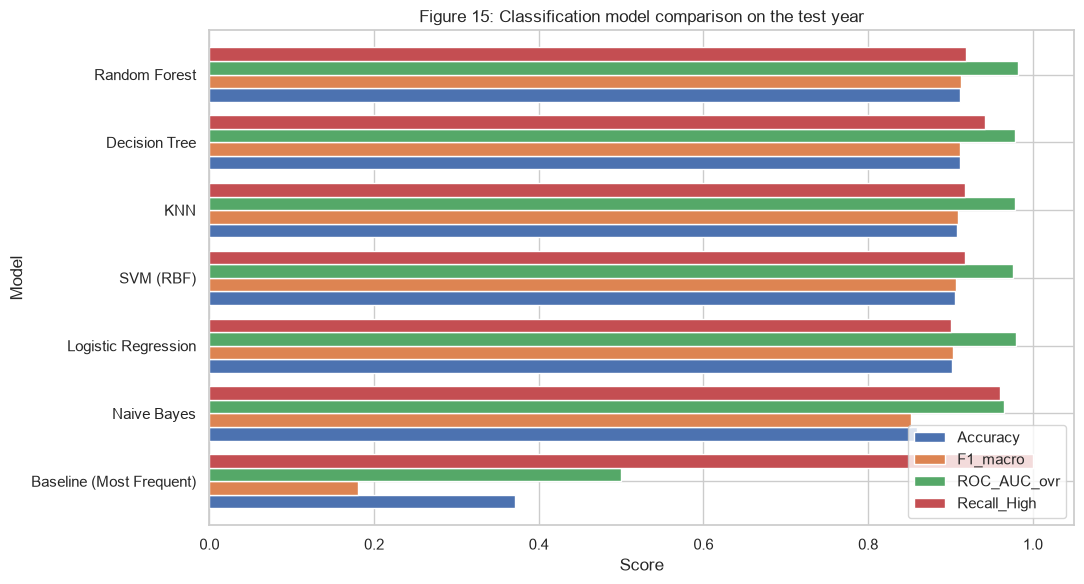

In [5]:
plot_cols = ["Accuracy", "F1_macro", "ROC_AUC_ovr", "Recall_High"]
res[plot_cols].sort_values("F1_macro").plot(kind="barh", figsize=(11, 6), width=0.8)
plt.title("Figure 15: Classification model comparison on the test year")
plt.xlim(0, 1.05); plt.xlabel("Score")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(IMG + "04_classification_comparison.png", dpi=120)
plt.show()

**Interpretation of the comparison**
* **Baseline** always says "High": accuracy 0.371, macro F1 0.18, ROC-AUC 0.50 (= random guessing).
  Its High-recall of 1.0 is meaningless – it never predicts anything else. This is why we use **macro F1**,
  not just one metric.
* **Logistic Regression** (F1 0.903) – a linear model already works well thanks to one-hot `hour` and the
  `daytype_hour` interaction feature.
* **Naive Bayes** is the weakest (F1 0.852): it assumes features are independent, but our features are
  clearly related (e.g. `hour`, `hour_sin`, `is_rush_hour`). It has the highest High-recall (0.96) because it
  over-predicts High (more false alarms).
* **KNN** (k = 15), **SVM** (C = 1) and **Decision Tree** (depth 8) are all close at F1 ≈ 0.907–0.911.
* **Random Forest** is the best: **accuracy 0.912, macro F1 0.913, ROC-AUC 0.982**, High-recall 0.919.
  It also has the best cross-validation F1 (0.894), so the choice is not just luck on the test set.
* Random Forest train F1 (0.946) is a bit higher than test F1 (0.913) – mild overfitting from deep trees
  (max_depth 20), but test performance is still the best.
* ✅ Success criteria met: macro F1 0.913 ≥ 0.85 and High-recall 0.919 ≥ 0.85.

**Final model choice: Random Forest.** If interpretability were more important than the last 1% of F1,
the Decision Tree (F1 0.911) or Logistic Regression would be good alternatives.

## 4. Best model – detailed evaluation

In [6]:
best_name = res.drop(index="Baseline (Most Frequent)")["F1_macro"].idxmax()
best_model = fitted[best_name]
y_pred = best_model.predict(X_test)
print("Best model:", best_name, best_params[best_name], "\n")
print(classification_report(y_test, y_pred, labels=CLASSES, digits=3))

Best model: Random Forest {'max_depth': 20, 'min_samples_leaf': 1} 



              precision    recall  f1-score   support

         Low      0.958     0.956     0.957      2657
      Medium      0.869     0.862     0.865      2839
        High      0.912     0.919     0.916      3237

    accuracy                          0.912      8733
   macro avg      0.913     0.913     0.913      8733
weighted avg      0.912     0.912     0.912      8733



**Reading the classification report:** *Low* is easiest (F1 0.957) – night hours are clearly quiet.
*Medium* is hardest (F1 0.865) because it sits **between** two classes: an hour with 4400 vehicles (Medium)
and one with 4600 (High) look almost the same to the model, but fall on opposite sides of the 4500 threshold.

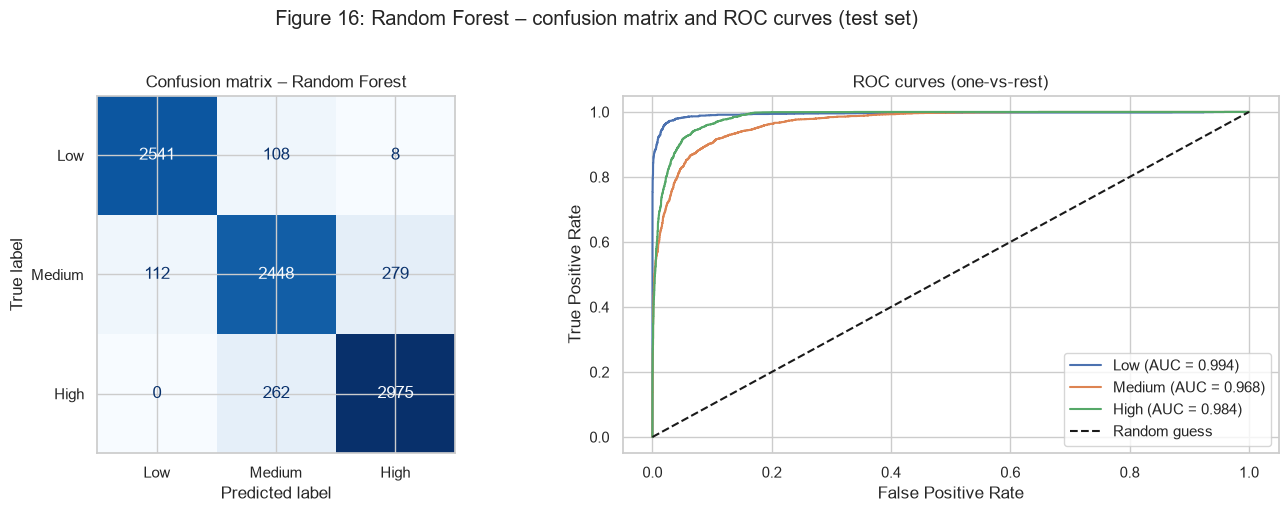

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=CLASSES, cmap="Blues", ax=axes[0],
                                        colorbar=False)
axes[0].set_title(f"Confusion matrix – {best_name}")
proba = proba_in_class_order(best_model, X_test)
y_bin = label_binarize(y_test, classes=CLASSES)
for i, c in enumerate(CLASSES):
    fpr, tpr, _ = roc_curve(y_bin[:, i], proba[:, i])
    auc = roc_auc_score(y_bin[:, i], proba[:, i])
    axes[1].plot(fpr, tpr, label=f"{c} (AUC = {auc:.3f})")
axes[1].plot([0, 1], [0, 1], "k--", label="Random guess")
axes[1].set_xlabel("False Positive Rate"); axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("ROC curves (one-vs-rest)"); axes[1].legend()
plt.suptitle(f"Figure 16: {best_name} – confusion matrix and ROC curves (test set)", y=1.02)
plt.tight_layout()
plt.savefig(IMG + "04_best_classifier_cm_roc.png", dpi=120, bbox_inches="tight")
plt.show()

**Interpretation:** in the confusion matrix almost all mistakes are between **neighbouring** classes
(Low↔Medium, Medium↔High); Low is very rarely confused with High (only 8 Low hours predicted as High, and **0** High hours predicted as Low). ROC-AUC is above 0.95 for every class,
meaning the model ranks congested hours above non-congested ones very reliably.

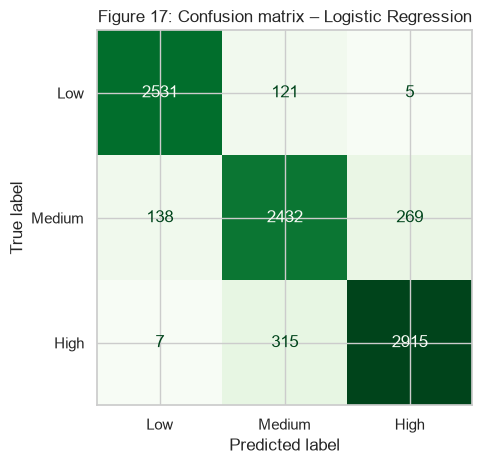

In [8]:
# Confusion matrix of the simplest strong model too, for comparison
ConfusionMatrixDisplay.from_predictions(y_test, fitted["Logistic Regression"].predict(X_test), labels=CLASSES,
                                        cmap="Greens", colorbar=False)
plt.title("Figure 17: Confusion matrix – Logistic Regression")
plt.tight_layout()
plt.savefig(IMG + "04_logreg_cm.png", dpi=120)
plt.show()

## 5. What did the model learn? – feature importance and a small tree

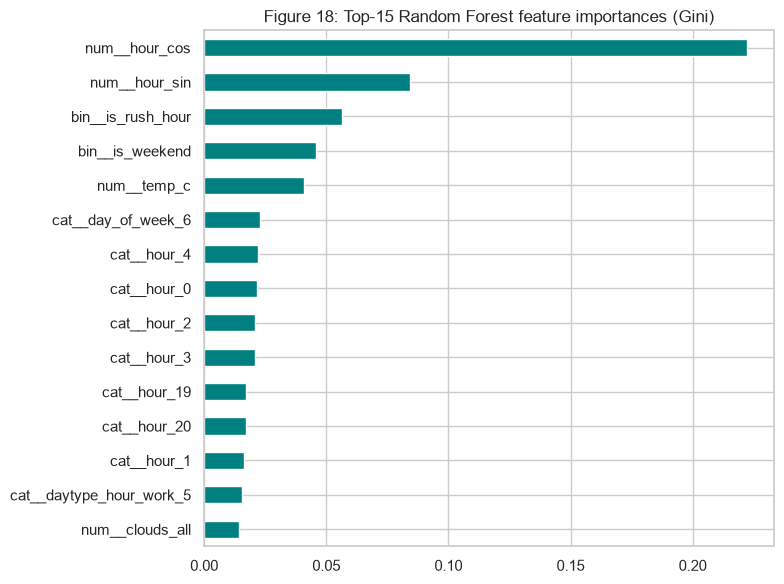

In [9]:
rf = fitted["Random Forest"]
names = rf.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf.named_steps["model"].feature_importances_, index=names).sort_values(ascending=False)
imp.head(15).sort_values().plot(kind="barh", figsize=(8, 6), color="teal")
plt.title("Figure 18: Top-15 Random Forest feature importances (Gini)")
plt.tight_layout()
plt.savefig(IMG + "04_rf_feature_importance.png", dpi=120)
plt.show()

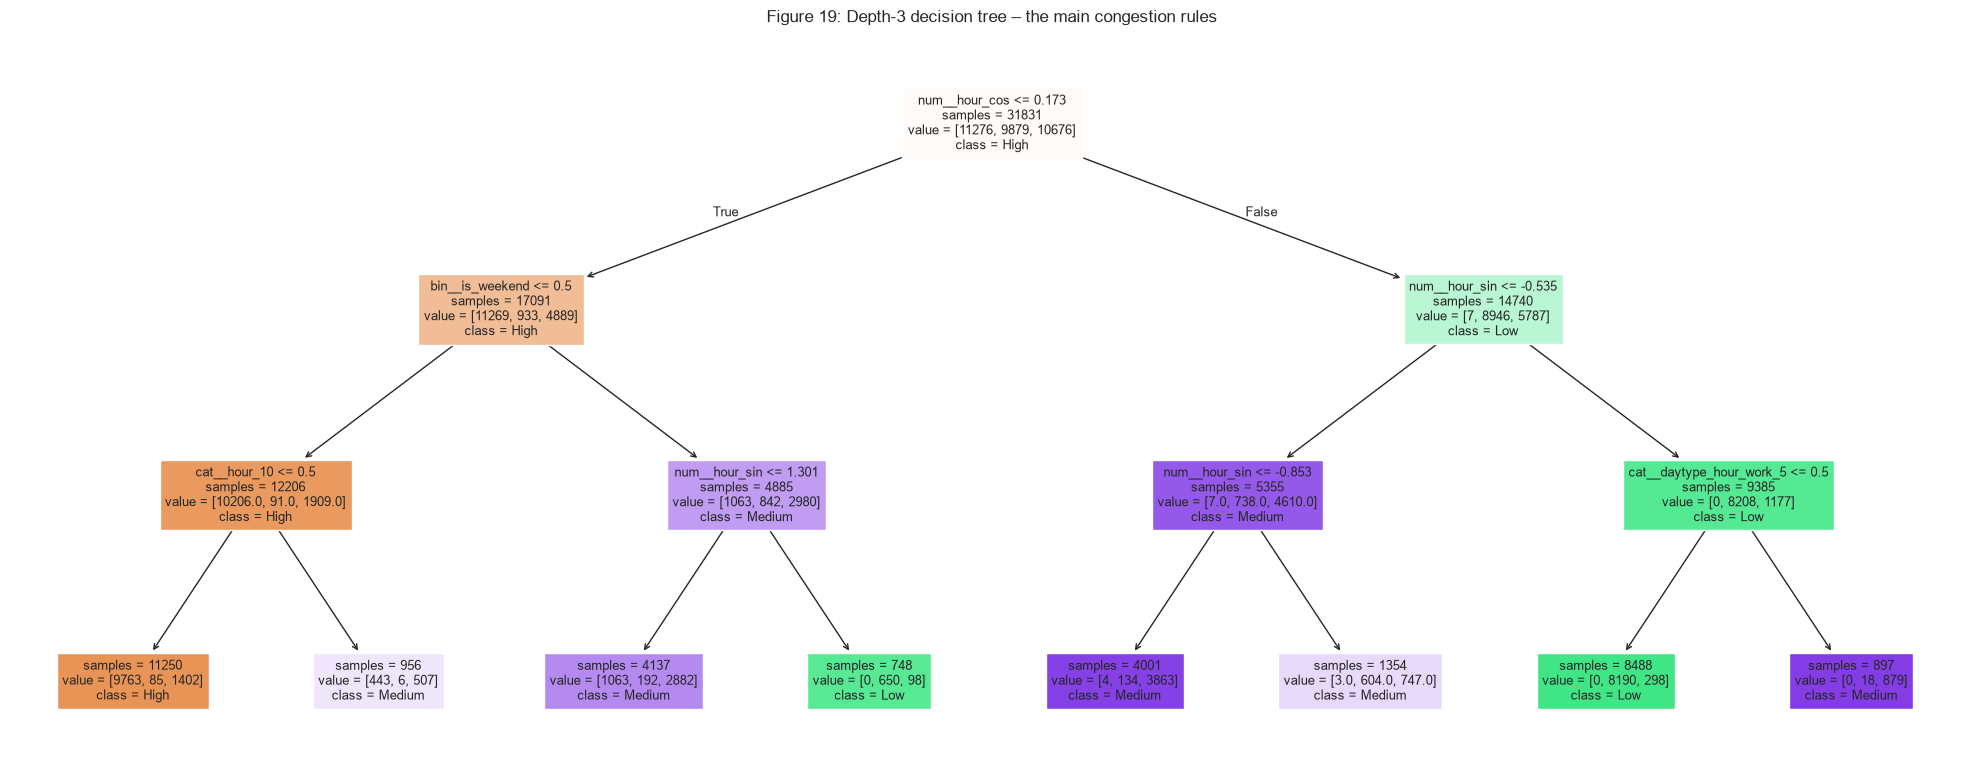

Depth-3 tree test accuracy: 0.86


In [10]:
# A small depth-3 tree is easy to read and explains the main rules
small = make_pipe(DecisionTreeClassifier(max_depth=3, random_state=mu.RANDOM_STATE)).fit(X_train, y_train)
plt.figure(figsize=(20, 8))
plot_tree(small.named_steps["model"], feature_names=small.named_steps["prep"].get_feature_names_out(),
          class_names=list(small.named_steps["model"].classes_), filled=True, fontsize=9, impurity=False)
plt.title("Figure 19: Depth-3 decision tree – the main congestion rules")
plt.tight_layout()
plt.savefig(IMG + "04_small_tree.png", dpi=100)
plt.show()
print("Depth-3 tree test accuracy:", round(accuracy_score(y_test, small.predict(X_test)), 3))

**Interpretation:** even a tiny tree with only 3 levels of if-else rules reaches **86% accuracy**.
Its first splits use the time features (night hours vs day hours, working day vs off day) – the same
rules we saw in the EDA heatmap. Deeper trees and forests add the finer details.

## 6. Extra check – can the regression model classify congestion too?
Predict the volume with the Module-1 regressor, then apply the same Low/Medium/High thresholds.

In [11]:
reg = joblib.load("../models/regressor.joblib")
reg_cls = dp.make_congestion_label(pd.Series(reg.predict(X_test), index=X_test.index))
print("Regression → class  Accuracy:", round(accuracy_score(y_test, reg_cls), 3),
      " F1-macro:", round(f1_score(y_test, reg_cls, average="macro"), 3))

Regression → class  Accuracy: 0.915  F1-macro: 0.916


**Interpretation:** turning the Random Forest *regression* prediction into a class gives
**accuracy 0.915 / F1 0.916** – slightly better than the best direct classifier (0.913). The regressor knows
the *exact* predicted volume, so it uses the ordering Low < Medium < High, which a normal classifier
ignores. Both approaches agree, which increases our confidence in the results.

**Limitations of Module 2:** the class thresholds (2000 / 4500) are our own choice for this road, not an
official standard; hours close to a threshold are naturally hard to classify; the same data limitations as
Module 1 apply (no accidents/events data, weak snow recording, one road only).

In [12]:
joblib.dump(best_model, "../models/classifier.joblib")
with open("../models/best_params_classification.json", "w") as f:
    json.dump({"best_model": best_name, "params": best_params}, f, indent=2, default=str)
print("Saved models/classifier.joblib")

Saved models/classifier.joblib
